In [1]:
#imports
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')


In [2]:
#dataset
dataset = pd.read_csv('./train.csv')

print(f'{dataset.describe()}\n')
print(f'{dataset.info()}\n')
print(f'{dataset.isnull().sum()}\n')

dataset.drop(labels='id',axis=1)

                  id           Time             V1             V2  \
count  227845.000000  227845.000000  227845.000000  227845.000000   
mean   113923.000000   94792.551673       0.000916      -0.000384   
std     65773.330379   47488.471663       1.958337       1.656602   
min         1.000000       0.000000     -56.407510     -72.715728   
25%     56962.000000   54161.000000      -0.919918      -0.597971   
50%    113923.000000   84707.000000       0.017978       0.066050   
75%    170884.000000  139305.000000       1.315548       0.803898   
max    227845.000000  172792.000000       2.454930      22.057729   

                  V3             V4             V5             V6  \
count  227845.000000  227845.000000  227845.000000  227845.000000   
mean       -0.000920      -0.001458       0.000997      -0.000613   
std         1.514545       1.415853       1.387667       1.336803   
min       -48.325589      -5.683171    -113.743307     -26.160506   
25%        -0.890786      -0.8492

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,143352.0,1.955041,-0.380783,-0.315013,0.330155,-0.509374,-0.086197,-0.627978,0.035994,1.054560,...,0.238197,0.968305,0.053208,-0.278602,-0.044999,-0.216780,0.045168,-0.047145,9.99,0
1,117173.0,-0.400975,-0.626943,1.555339,-2.017772,-0.107769,0.168310,0.017959,-0.401619,0.040378,...,-0.153485,0.421703,0.113442,-1.004095,-1.176695,0.361924,-0.370469,-0.144792,45.90,0
2,149565.0,0.072509,0.820566,-0.561351,-0.709897,1.080399,-0.359429,0.787858,0.117276,-0.131275,...,-0.314638,-0.872959,0.083391,0.148178,-0.431459,0.119690,0.206395,0.070288,11.99,0
3,93670.0,-0.535045,1.014587,1.750679,2.769390,0.500089,1.002270,0.847902,-0.081323,0.371579,...,0.063525,0.443431,-0.072754,0.448192,-0.655203,-0.181038,-0.093013,-0.064931,117.44,0
4,82655.0,-4.026938,1.897371,-0.429786,-0.029571,-0.855751,-0.480406,-0.435632,1.313760,0.536044,...,-0.480691,-0.230369,0.250717,0.066399,0.470787,0.245335,0.286904,-0.322672,25.76,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
227840,75618.0,1.173488,0.100792,0.490512,0.461596,-0.296377,-0.213165,-0.165254,0.119221,-0.114199,...,-0.186027,-0.574283,0.161405,-0.006140,0.091444,0.109235,-0.020922,0.003967,1.98,0
227841,159000.0,-0.775981,0.144023,-1.142399,-1.241113,1.940358,3.912076,-0.466107,1.360620,0.400697,...,0.037078,-0.019575,0.241830,0.682820,-1.635109,-0.770941,0.066006,0.137056,89.23,0
227842,79795.0,-0.146609,0.992946,1.524591,0.485774,0.349308,-0.815198,1.076640,-0.395316,-0.491303,...,0.052649,0.354089,-0.291198,0.402849,0.237383,-0.398467,-0.121139,-0.196195,3.94,0
227843,87931.0,-2.948638,2.354849,-2.521201,-3.798905,1.866302,2.727695,-0.471769,2.217537,0.580199,...,-0.332759,-1.047514,0.143326,0.678869,0.319710,0.426309,0.496912,0.335822,1.00,0


In [3]:
class_counts = dataset['Class'].value_counts()

print(f'{class_counts}\n')

Class
0    227451
1       394
Name: count, dtype: int64



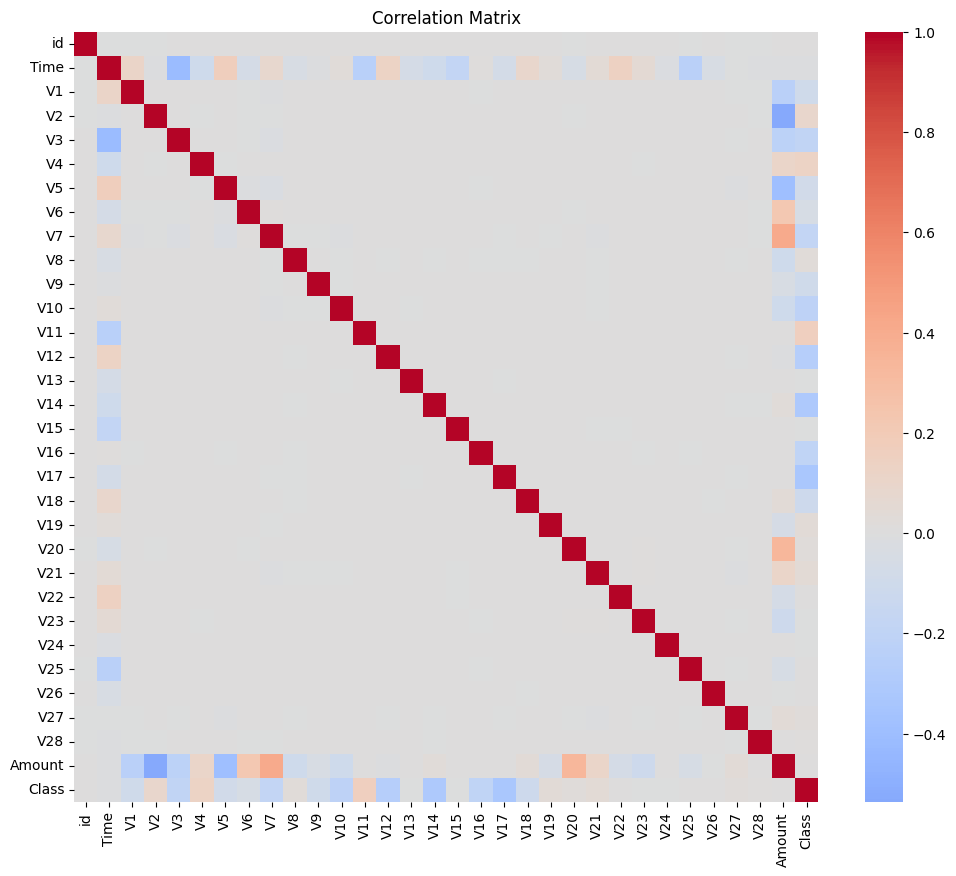

In [4]:
plt.figure(figsize=(12,10))
sns.heatmap(dataset.corr(numeric_only=True), cmap='coolwarm', center=0, annot=False)
plt.title("Correlation Matrix")
plt.show()

In [6]:
#Subtask 1
mean_legit = dataset.loc[dataset['Class'] == 0, 'Amount'].mean()
answer = (dataset['Class'] == 1) & (dataset['Amount'] > mean_legit)
answer = answer.sum()
task1 = pd.DataFrame({
    'subtaskID': [1],
    'datapointID': [1],
    'answer': answer
})

In [12]:
#Subtask 2
frauds = dataset[dataset['Class'] == 1]
features = [f'V{i}' for i in range (1,29)] + ['Amount']
X = frauds[features].values

mean_vector = np.mean(X,axis=0)
cov_matrix = np.cov(X,rowvar=False)

inv_cov_matrix = np.linalg.pinv(cov_matrix)

diff = X - mean_vector

mahalanobis_distance = np.sqrt(np.sum(np.dot(diff, inv_cov_matrix) * diff, axis=1))
mean_md = np.mean(mahalanobis_distance)

task2 = pd.DataFrame({
    'subtaskID': [2],
    'datapointID': [2],
    'answer': mean_md
})

In [9]:
#Subtask 3
X = dataset.drop(columns=(['id','Class']))
y = dataset['Class']

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=4,
    min_samples_split=5,
    n_jobs=-1
)
forest.fit(X_train, y_train)

y_pred = forest.predict(X_test)

print(f'F1 Score: {f1_score(y_pred, y_test)}')

F1 Score: 0.8571428571428571


In [10]:
pred_df = pd.read_csv('test.csv')
X = pred_df.drop(columns = ['id'])
preds = forest.predict(X)

task3 = pd.DataFrame({
    'subtaskID': 3,
    'datapointID': pred_df['id'],
    'answer': preds
})

In [13]:
#submission
submission = pd.concat((task1,task2,task3))
submission.columns = ['subtaskID','datapointID','answer']
submission.to_csv('submission.csv',index=False)